# Fast Retrieval Layer

**Note:** T2I doesn't ship the original images only 200-dim embeddings.
So I will provide the visualisation of the vector (PCA projections) rather than actual images. (meaning only distances are real, not pixels )

In [4]:
import sys
sys.path.insert(0, '../src')

import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

import faiss
from sklearn.decomposition import PCA

from data.formats import read_fbin
from data.ground_truth import compute_gt, recall_at_k
from indexer import load_index
from retriever import Retriever
from config import Metric

DATA_DIR = Path('../data')
INDEX_DIR = Path('../index/t2i-100k')
BENCH_DIR = Path('../benchmark_results')

print('Imports OK')

Imports OK


#### 1. Load the data

In [ ]:
base = read_fbin(DATA_DIR / 't2i_base_100000.fbin')
queries = read_fbin(DATA_DIR / 't2i_queries_10000.fbin')

print(f'Base vectors: {base.shape} dtype={base.dtype}')
print(f'Query vectors: {queries.shape} dtype={queries.dtype}')
print(f'\nBase L2 norm mean: {np.linalg.norm(base, axis=1).mean():.4f}') # Query vectors are L2-normalised by the CLIP encoder (~1.0).
print(f'Query L2 norm mean: {np.linalg.norm(queries, axis=1).mean():.4f}') # Base vectors are raw from the .fbin file; the indexer normalises them at build time (hence ~0.966, not exactly 1.0).'

Base vectors: (100000, 200) dtype=float32
Query vectors: (10000, 200) dtype=float32

Base L2 norm mean: 0.9660
Query L2 norm mean: 1.0000


#### 2. PCA — what the 200-dim space looks like in 2D

We project 3000 base vectors and 300 queries into 2D with PCA.
Colour = IVF cluster assignment (which Voronoi cell the vector lives in).

In [18]:
index, fp16_store, meta = load_index(INDEX_DIR)
print(f'Index: {meta.factory_string} n={meta.n:,} nlist={meta.nlist} pq_m={meta.pq_m}')

# Sample for PCA (full 100K is slow for PCA, so 3000 base vectors and 300 queries)
rng = np.random.default_rng(0)
sample_idx = rng.choice(len(base), size=3000, replace=False)
sample_base = base[sample_idx].astype(np.float32)
sample_queries = queries[:300].astype(np.float32)

# l2 norm same as indexer
def l2_norm(v):
    n = np.linalg.norm(v, axis=1, keepdims=True)
    return v / np.where(n == 0, 1, n)

sample_base_n = l2_norm(sample_base)
sample_queries_n = l2_norm(sample_queries)

# IVF cluster assignments for the sample
iv = faiss.extract_index_ivf(index)
_, cluster_ids = iv.quantizer.search(sample_base_n, 1)
# print(cluster_ids)
cluster_ids = cluster_ids[:, 0]

# PCA to 2D
all_vecs = np.vstack([sample_base_n, sample_queries_n])
pca = PCA(n_components=2, random_state=0)
all_2d = pca.fit_transform(all_vecs)

base_2d = all_2d[:len(sample_base_n)]
query_2d = all_2d[len(sample_base_n):]

print(f'PCA explained variance: {pca.explained_variance_ratio_.sum()*100:.1f}% in 2 components') # High-dim data always loses most variance in 2D — the structure is real, just compressed

Index: IVF512,PQ25x8 n=100,000 nlist=512 pq_m=25
PCA explained variance: 8.0% in 2 components


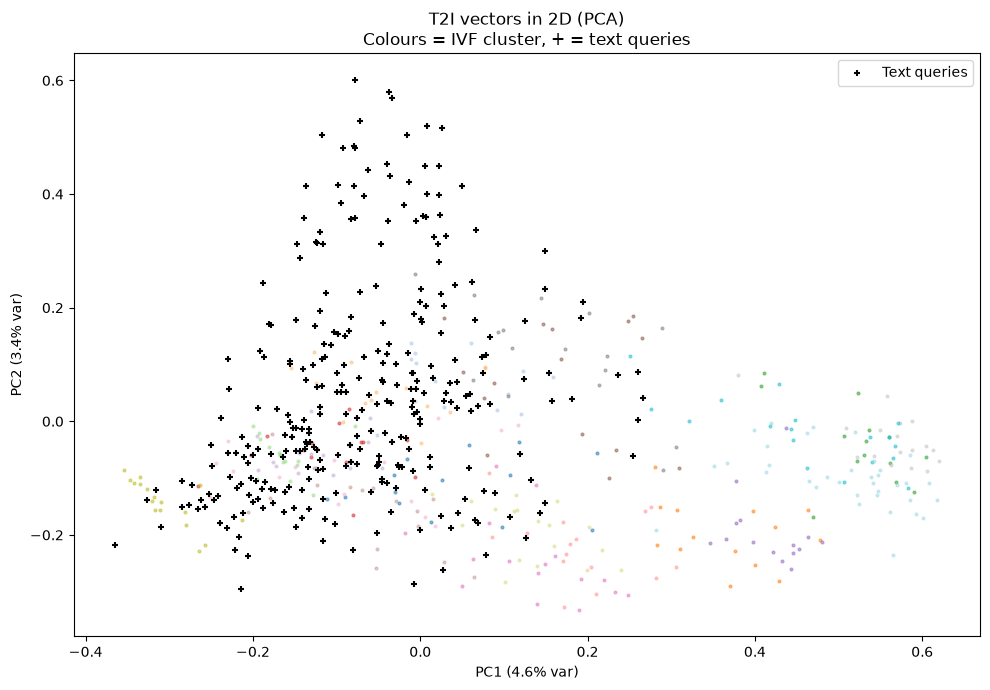


Key observation: clusters are real (k-means found structure).
Queries (text) broadly overlap with base (images) but are NOT perfectly aligned.
That offset is the cross-modal gap.


In [19]:
fig, ax = plt.subplots(figsize=(10, 7))

# top-20 clusters by colour, rest grey
top_clusters = np.bincount(cluster_ids).argsort()[-20:]
cmap = plt.cm.tab20(np.linspace(0, 1, 20))

for i, cid in enumerate(top_clusters):
    mask = cluster_ids == cid
    ax.scatter(base_2d[mask, 0], base_2d[mask, 1], s=4, alpha=0.5, color=cmap[i])

# Queries on top
ax.scatter(query_2d[:, 0], query_2d[:, 1], s=20, color='black', marker='+', label='Text queries', zorder=5)

ax.set_title('T2I vectors in 2D (PCA)\nColours = IVF cluster, + = text queries')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

print('\nKey observation: clusters are real (k-means found structure).')
print('Queries (text) broadly overlap with base (images) but are NOT perfectly aligned.')
print('That offset is the cross-modal gap.')

#### 3. One query: what does ANN return vs ground truth?

In [33]:
QUERY_IDX = 42
K = 10

qv = l2_norm(queries[QUERY_IDX:QUERY_IDX+1].astype(np.float32))

# Ground truth: exact brute-force
print('Computing exact GT (brute-force over 100K vectors)...')
gt_single = compute_gt(l2_norm(base.astype(np.float32)), qv, k=K, metric=Metric.IP)
gt_ids = gt_single[0]   # true top-10 IDs
print(f'True top-{K} IDs: {gt_ids}')

# ANN without rerank
retriever = Retriever(INDEX_DIR)
retriever.set_nprobe(64)

resp_ann = retriever.search(qv, k=K, do_rerank=False)
ann_ids = np.array([r.frame_id for r in resp_ann.results])
ann_scores = np.array([r.score   for r in resp_ann.results])

# ANN with rerank
resp_rr = retriever.search(qv, k=K, do_rerank=True)
rr_ids = np.array([r.frame_id for r in resp_rr.results])
rr_scores = np.array([r.score   for r in resp_rr.results])

gt_set = set(gt_ids.tolist())
hits_ann = [fid in gt_set for fid in ann_ids]
hits_rr = [fid in gt_set for fid in rr_ids]

print(f'\nANN top-{K}:', [(int(fid), f'{sc:.4f}', 'H' if hit else 'NH') for fid, sc, hit in zip(ann_ids, ann_scores, hits_ann)])
print(f'Reranked top-{K}:', [(int(fid), f'{sc:.4f}') for fid, sc in zip(rr_ids, rr_scores)])
print(f'\nANN hits: {sum(hits_ann)}/{K}  ({sum(hits_ann)/K*100:.0f}% recall)')
print(f'RR hits: {sum(hits_rr)}/{K} ({sum(hits_rr)/K*100:.0f}% recall)')

Computing exact GT (brute-force over 100K vectors)...
True top-10 IDs: [81056 40074  4153 46075 22306  1882 67965 27452 92356  4052]

ANN top-10: [(46075, '0.4711', 'H'), (75523, '0.4594', 'NH'), (40074, '0.4571', 'H'), (30795, '0.4556', 'NH'), (89199, '0.4547', 'NH'), (51545, '0.4481', 'NH'), (52166, '0.4468', 'NH'), (22306, '0.4462', 'H'), (1882, '0.4435', 'H'), (86813, '0.4434', 'NH')]
Reranked top-10: [(81056, '0.5070'), (40074, '0.4862'), (4153, '0.4750'), (46075, '0.4744'), (22306, '0.4707'), (1882, '0.4550'), (67965, '0.4501'), (27452, '0.4500'), (92356, '0.4446'), (4052, '0.4416')]

ANN hits: 4/10  (40% recall)
RR hits: 10/10 (100% recall)


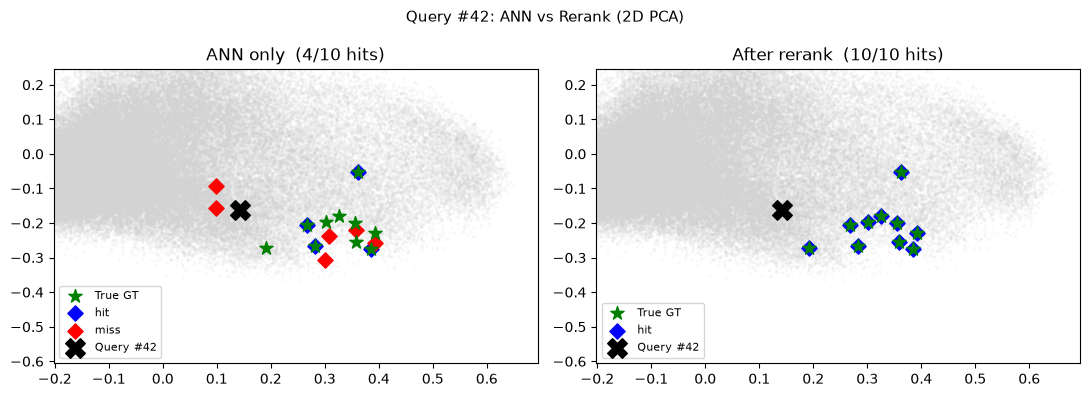

In [34]:
all_vecs_full = np.vstack([l2_norm(base.astype(np.float32)), qv])
all_2d_full = pca.transform(all_vecs_full)
base_2d_full  = all_2d_full[:len(base)]
query_2d_full = all_2d_full[len(base):]

gt_2d = base_2d_full[gt_ids]
all_pts = np.vstack([gt_2d, base_2d_full[ann_ids], query_2d_full])
pad = 0.3
xlim = (all_pts[:, 0].min()-pad, all_pts[:, 0].max()+pad)
ylim = (all_pts[:, 1].min()-pad, all_pts[:, 1].max()+pad)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, ids, hits, title in [
    (axes[0], ann_ids, hits_ann, f'ANN only  ({sum(hits_ann)}/{K} hits)'),
    (axes[1], rr_ids,  hits_rr,  f'After rerank  ({sum(hits_rr)}/{K} hits)'),
]:
    ax.scatter(base_2d_full[:, 0], base_2d_full[:, 1], s=2, alpha=0.08, color='lightgrey')
    ax.scatter(gt_2d[:, 0], gt_2d[:, 1], s=100, color='green', marker='*', label='True GT', zorder=4)
    for i, (fid, hit) in enumerate(zip(ids, hits)):
        pt = base_2d_full[fid]
        ax.scatter(pt[0], pt[1], s=60, color='blue' if hit else 'red', marker='D', zorder=3,
                   label=('hit' if hit else 'miss') if i == 0 or (i == 1 and not hit) else '_')
    ax.scatter(query_2d_full[0, 0], query_2d_full[0, 1], s=200, color='black', marker='X', zorder=5, label=f'Query #{QUERY_IDX}')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_title(title)
    ax.legend(fontsize=8)

plt.suptitle(f'Query #{QUERY_IDX}: ANN vs Rerank (2D PCA)', fontsize=11)
plt.tight_layout()
plt.show()

#### 5. B1 recall curve — the full sweep

Load the pre-computed B1 results and plot recall vs latency.

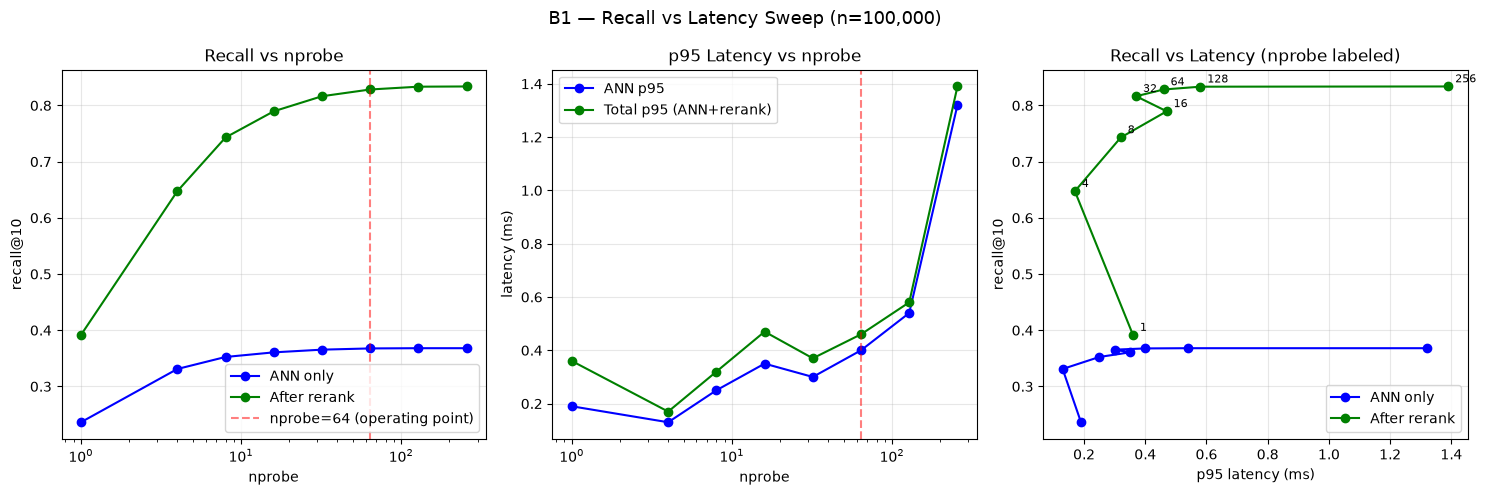

Operating point: nprobe=64 recall_rr=0.828 p95=0.5ms


In [37]:
b1 = json.loads((BENCH_DIR / 'b1_t2i-100k.json').read_text())
sweep = b1['sweep']

nprobes = [r['nprobe'] for r in sweep]
recall_ann = [r['recall_ann'] for r in sweep]
recall_rr = [r['recall_reranked'] for r in sweep]
ann_p95 = [r['ann_p95_ms'] for r in sweep]
total_p95 = [r['total_p95_ms'] for r in sweep]
mean_ndis = [r['mean_ndis'] for r in sweep]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Recall vs nprobe
ax = axes[0]
ax.plot(nprobes, recall_ann, 'b-o', label='ANN only')
ax.plot(nprobes, recall_rr, 'g-o', label='After rerank')
ax.axvline(64, color='red', linestyle='--', alpha=0.5, label='nprobe=64 (operating point)')
ax.set_xlabel('nprobe')
ax.set_ylabel('recall@10')
ax.set_title('Recall vs nprobe')
ax.legend()
ax.set_xscale('log')
ax.grid(alpha=0.3)

# p95 latency vs nprobe
ax = axes[1]
ax.plot(nprobes, ann_p95, 'b-o', label='ANN p95')
ax.plot(nprobes, total_p95, 'g-o', label='Total p95 (ANN+rerank)')
ax.axvline(64, color='red', linestyle='--', alpha=0.5)
ax.set_xlabel('nprobe')
ax.set_ylabel('latency (ms)')
ax.set_title('p95 Latency vs nprobe')
ax.legend()
ax.set_xscale('log')
ax.grid(alpha=0.3)

# Recall vs latency (the real tradeoff curve)
ax = axes[2]
ax.plot(ann_p95, recall_ann, 'b-o', label='ANN only')
ax.plot(total_p95, recall_rr, 'g-o', label='After rerank')

for i, nprobe in enumerate(nprobes):
    ax.annotate(str(nprobe), (total_p95[i], recall_rr[i]), textcoords='offset points', xytext=(5, 3), fontsize=8)

ax.set_xlabel('p95 latency (ms)')
ax.set_ylabel('recall@10')
ax.set_title('Recall vs Latency (nprobe labeled)')
ax.legend()
ax.grid(alpha=0.3)

plt.suptitle(f'B1 — Recall vs Latency Sweep (n={b1["index_meta"]["n"]:,})', fontsize=13)
plt.tight_layout()
plt.show()

print(f'Operating point: nprobe=64 recall_rr={recall_rr[nprobes.index(64)]:.3f} p95={total_p95[nprobes.index(64)]:.1f}ms')

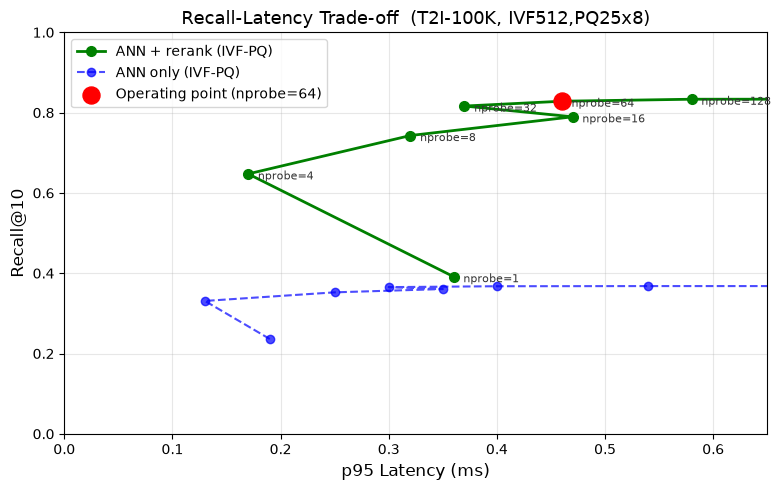

Saved to ../docs/recall_latency_curve.png


In [39]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(total_p95, recall_rr, 'g-o', linewidth=2, markersize=7, label='ANN + rerank (IVF-PQ)')
ax.plot(ann_p95, recall_ann, 'b--o', linewidth=1.5, markersize=6, alpha=0.7, label='ANN only (IVF-PQ)')

for i, nprobe in enumerate(nprobes):
    ax.annotate(f'nprobe={nprobe}', (total_p95[i], recall_rr[i]), textcoords='offset points', xytext=(7, -4), fontsize=8, color='#333')

op_idx = nprobes.index(64)
ax.scatter([total_p95[op_idx]], [recall_rr[op_idx]], s=150, color='red', zorder=5, label='Operating point (nprobe=64)')

ax.set_xlabel('p95 Latency (ms)', fontsize=12)
ax.set_ylabel('Recall@10', fontsize=12)
ax.set_title('Recall-Latency Trade-off  (T2I-100K, IVF512,PQ25x8)', fontsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
ax.set_ylim(0, 1.0)
ax.set_xlim(0, 0.65)
plt.tight_layout()

out = Path('../docs/recall_latency_curve.png')
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to {out}')

#### 6. ndis vs nprobe — the cost model input

ndis = number of PQ codes scanned. Grows linearly with nprobe.
This is what B3 uses to project latency at 100M scale.

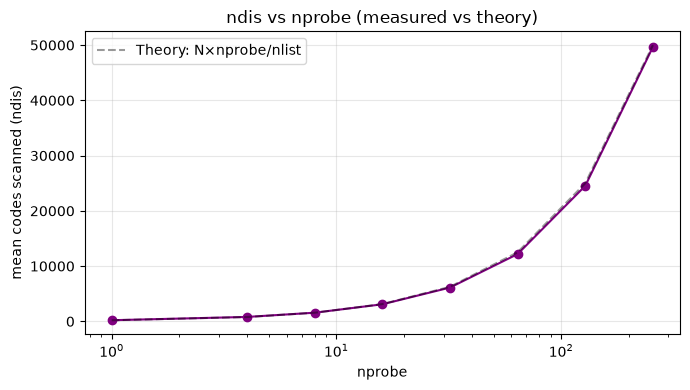

ndis scales linearly with nprobe — validates the cost model.
At 100M vectors with same nprobe/nlist ratio:
nprobe=  1 ndis@100M ≈ 0.2M codes
nprobe=  4 ndis@100M ≈ 0.8M codes
nprobe=  8 ndis@100M ≈ 1.6M codes
nprobe= 16 ndis@100M ≈ 3.1M codes
nprobe= 32 ndis@100M ≈ 6.1M codes
nprobe= 64 ndis@100M ≈ 12.2M codes
nprobe=128 ndis@100M ≈ 24.5M codes
nprobe=256 ndis@100M ≈ 49.7M codes


In [43]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(nprobes, mean_ndis, 'purple', marker='o')

# Theoretical: ndis = N * nprobe / nlist
N = b1['index_meta']['n']
nlist = b1['index_meta']['nlist']
theory = [N * np / nlist for np in nprobes]
ax.plot(nprobes, theory, 'k--', alpha=0.4, label=f'Theory: N×nprobe/nlist')

ax.set_xlabel('nprobe')
ax.set_ylabel('mean codes scanned (ndis)')
ax.set_title('ndis vs nprobe (measured vs theory)')
ax.set_xscale('log')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('ndis scales linearly with nprobe — validates the cost model.')
print(f'At 100M vectors with same nprobe/nlist ratio:')
scale_factor = 100_000_000 / N
for row in sweep:
    proj_ndis = row['mean_ndis'] * scale_factor
    print(f'nprobe={row["nprobe"]:3d} ndis@100M ≈ {proj_ndis/1e6:.1f}M codes')

#### 7. Score distribution — base vs queries

Computing GT for 100 queries...


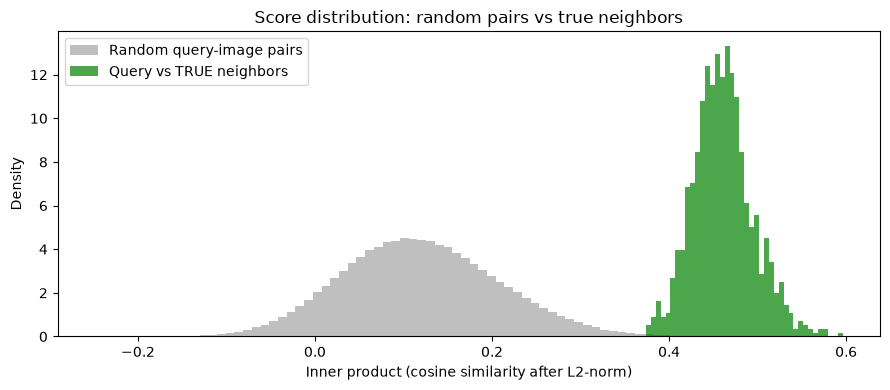

Random pairs: mean=0.1197  std=0.0883
True neighbors: mean=0.4610  std=0.0339

Grey = query vs a random image. Score near 0 — most images are unrelated to the query.
Green = query vs its true matching images. Score ~0.45 — CLIP pushes matches close together.

The gap is large and clear — in exact scores, true matches are easy to identify.
ANN recall is still low (0.37) because PQ compression distorts scores: a true match at 0.45
might get compressed to 0.42, while a non-match gets bumped from 0.35 to 0.44.
Within the scanned candidates the ordering scrambles. Rerank recomputes exact scores and fixes it.


In [50]:
base_n = l2_norm(base[:5000].astype(np.float32))
queries_n = l2_norm(queries[:100].astype(np.float32))

print('Computing GT for 100 queries...')
gt_100 = compute_gt(l2_norm(base.astype(np.float32)), queries_n, k=10, metric=Metric.IP)

# Random scores: query x random image
random_scores = (queries_n @ base_n.T).flatten()

# GT scores: query x its true top-10 images
gt_scores = []
for qi, gt_row in enumerate(gt_100):
    qv_i = queries_n[qi]
    gt_vecs = l2_norm(base[gt_row].astype(np.float32))
    gt_scores.extend((gt_vecs @ qv_i).tolist())

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(random_scores, bins=80, density=True, alpha=0.5, color='grey', label='Random query-image pairs')
ax.hist(gt_scores, bins=40, density=True, alpha=0.7, color='green', label='Query vs TRUE neighbors')
ax.set_xlabel('Inner product (cosine similarity after L2-norm)')
ax.set_ylabel('Density')
ax.set_title('Score distribution: random pairs vs true neighbors')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Random pairs: mean={random_scores.mean():.4f}  std={random_scores.std():.4f}')
print(f'True neighbors: mean={np.mean(gt_scores):.4f}  std={np.std(gt_scores):.4f}')
print()
print('Grey = query vs a random image. Score near 0 — most images are unrelated to the query.')
print('Green = query vs its true matching images. Score ~0.45 — CLIP pushes matches close together.')
print()
print('The gap is large and clear — in exact scores, true matches are easy to identify.')
print('ANN recall is still low (0.37) because PQ compression distorts scores: a true match at 0.45')
print('might get compressed to 0.42, while a non-match gets bumped from 0.35 to 0.44.')
print('Within the scanned candidates the ordering scrambles. Rerank recomputes exact scores and fixes it.')